<a href="https://colab.research.google.com/github/VidhiSidana/UCS420/blob/main/assignment8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Cleaned Text:
 artificial intelligence is transforming the modern world
it helps computers learn from data and solve complex problems
ai is used in healthcare education transportation and business
it makes technology smarter and improves human productivity
i believe artificial intelligence will create exciting opportunities
and change the way people live and work

Word Tokens:
 ['artificial', 'intelligence', 'is', 'transforming', 'the', 'modern', 'world', 'it', 'helps', 'computers', 'learn', 'from', 'data', 'and', 'solve', 'complex', 'problems', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'transportation', 'and', 'business', 'it', 'makes', 'technology', 'smarter', 'and', 'improves', 'human', 'productivity', 'i', 'believe', 'artificial', 'intelligence', 'will', 'create', 'exciting', 'opportunities', 'and', 'change', 'the', 'way', 'people', 'live', 'and', 'work']

Sentence Tokens:
 ['Artificial Intelligence is transforming the modern world.', 'It helps computers learn from data 

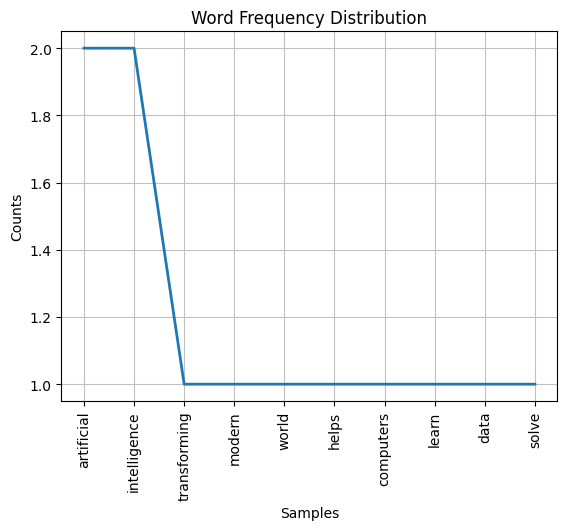

In [1]:
import re
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
text = """Artificial Intelligence is transforming the modern world.
It helps computers learn from data and solve complex problems.
AI is used in healthcare, education, transportation, and business.
It makes technology smarter and improves human productivity.
I believe Artificial Intelligence will create exciting opportunities
and change the way people live and work."""

clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Cleaned Text:\n", clean_text)

words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

split_words = clean_text.split()
nltk_words = word_tokenize(clean_text)

print("\nUsing split():", split_words)
print("\nUsing word_tokenize():", nltk_words)

stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in nltk_words
    if word not in stop_words
]

print("\nWords after Stopword Removal:\n", filtered_words)

fdist = FreqDist(filtered_words)

print("\nWord Frequency Distribution:")
for word, frequency in fdist.items():
    print(word, ":", frequency)

fdist.plot(10, title="Word Frequency Distribution")
plt.show()

In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
text = """Artificial Intelligence is transforming the modern world.
It helps computers learn from data and solve complex problems.
AI is used in healthcare, education, transportation, and business.
It makes technology smarter and improves human productivity.
I believe Artificial Intelligence will create exciting opportunities
and change the way people live and work."""
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

print("Extracted Words:\n", words)
stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in words
    if word not in stop_words
]

print("\nAfter Stopword Removal:\n", filtered_words)

ps = PorterStemmer()

stemmed_words = [
    ps.stem(word) for word in filtered_words
]

print("\nStemmed Words:\n", stemmed_words)

lemmatizer = WordNetLemmatizer()

lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered_words
]

print("\nLemmatized Words:\n", lemmatized_words)
print("\nComparison:")
for original, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(original, "-> Stem:", stem, "| Lemma:", lemma)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Extracted Words:
 ['artificial', 'intelligence', 'is', 'transforming', 'the', 'modern', 'world', 'it', 'helps', 'computers', 'learn', 'from', 'data', 'and', 'solve', 'complex', 'problems', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'transportation', 'and', 'business', 'it', 'makes', 'technology', 'smarter', 'and', 'improves', 'human', 'productivity', 'i', 'believe', 'artificial', 'intelligence', 'will', 'create', 'exciting', 'opportunities', 'and', 'change', 'the', 'way', 'people', 'live', 'and', 'work']

After Stopword Removal:
 ['artificial', 'intelligence', 'transforming', 'modern', 'world', 'helps', 'computers', 'learn', 'data', 'solve', 'complex', 'problems', 'ai', 'used', 'healthcare', 'education', 'transportation', 'business', 'makes', 'technology', 'smarter', 'improves', 'human', 'productivity', 'believe', 'artificial', 'intelligence', 'create', 'exciting', 'opportunities', 'change', 'way', 'people', 'live', 'work']

Stemmed Words:
 ['artifici', 'intellig', 'transform

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
texts = [
    "Artificial intelligence helps computers learn and solve problems.",
    "Machine learning improves predictions using data and algorithms.",
    "Deep learning uses neural networks to recognize images and patterns."
]
cv = CountVectorizer()
bow_matrix = cv.fit_transform(texts)

print("Bag of Words Representation:")
print(cv.get_feature_names_out())
print(bow_matrix.toarray())

tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(texts)
print("\nTF-IDF Representation:")
print(tfidf_matrix.toarray())

feature_names = tfidf.get_feature_names_out()

print("\nTop 3 Keywords from Each Text:")

for i in range(len(texts)):
    scores = tfidf_matrix[i].toarray().flatten()

    top_indices = scores.argsort()[-3:][::-1]

    print("\nText", i + 1)
    for index in top_indices:
        print(feature_names[index], ":", round(scores[index], 3))

Bag of Words Representation:
['algorithms' 'and' 'artificial' 'computers' 'data' 'deep' 'helps'
 'images' 'improves' 'intelligence' 'learn' 'learning' 'machine'
 'networks' 'neural' 'patterns' 'predictions' 'problems' 'recognize'
 'solve' 'to' 'uses' 'using']
[[0 1 1 1 0 0 1 0 0 1 1 0 0 0 0 0 0 1 0 1 0 0 0]
 [1 1 0 0 1 0 0 0 1 0 0 1 1 0 0 0 1 0 0 0 0 0 1]
 [0 1 0 0 0 1 0 1 0 0 0 1 0 1 1 1 0 0 1 0 1 1 0]]

TF-IDF Representation:
[[0.         0.21786941 0.36888498 0.36888498 0.         0.
  0.36888498 0.         0.         0.36888498 0.36888498 0.
  0.         0.         0.         0.         0.         0.36888498
  0.         0.36888498 0.         0.         0.        ]
 [0.37994462 0.22440141 0.         0.         0.37994462 0.
  0.         0.         0.37994462 0.         0.         0.28895767
  0.37994462 0.         0.         0.         0.37994462 0.
  0.         0.         0.         0.         0.37994462]
 [0.         0.19767284 0.         0.         0.         0.33468921
  0.    

Sentiment Analysis Results:

Review: This smartphone has an amazing camera and excellent battery life.
Polarity: 0.8
Subjectivity: 0.95
Sentiment: Positive
--------------------------------
Review: I love this product. It is very useful and easy to use.
Polarity: 0.441
Subjectivity: 0.478
Sentiment: Positive
--------------------------------
Review: The phone is terrible and its battery drains very quickly.
Polarity: -0.283
Subjectivity: 0.825
Sentiment: Negative
--------------------------------
Review: The product is disappointing and the performance is very poor.
Polarity: -0.56
Subjectivity: 0.74
Sentiment: Negative
--------------------------------
Review: The phone is okay and has average features.
Polarity: 0.175
Subjectivity: 0.45
Sentiment: Positive
--------------------------------


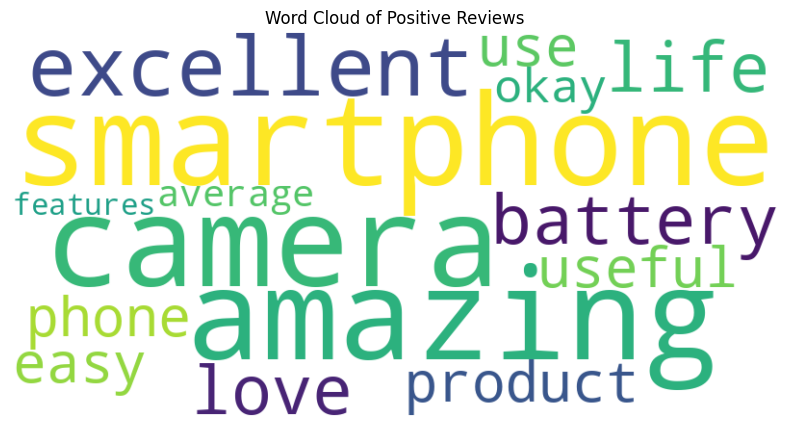

In [4]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt
reviews = [
    "This smartphone has an amazing camera and excellent battery life.",
    "I love this product. It is very useful and easy to use.",
    "The phone is terrible and its battery drains very quickly.",
    "The product is disappointing and the performance is very poor.",
    "The phone is okay and has average features."
]

positive_reviews = []

print("Sentiment Analysis Results:\n")
for review in reviews:

    blob = TextBlob(review)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity
    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)

    elif polarity < 0:
        sentiment = "Negative"

    else:
        sentiment = "Neutral"

    print("Review:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)
    print("--------------------------------")

positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='viridis'
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Positive Reviews")
plt.show()

In [7]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """
Artificial intelligence enables machines to learn from data.
AI uses algorithms to solve complex problems.
It is widely used in healthcare and education.
AI helps automate tasks and improve decision making.
It makes computers intelligent and efficient.
"""

text2 = """
Blockchain is a distributed digital ledger technology.
It stores information securely across multiple computers.
Blockchain uses cryptography to protect transactions.
It provides transparency and security.
It is widely used in digital currencies and finance.
"""
def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return set(text.split())

words1 = preprocess(text1)
words2 = preprocess(text2)

print("AI Tokens:", words1)
print("\nBlockchain Tokens:", words2)

intersection = words1.intersection(words2)
union = words1.union(words2)

jaccard = len(intersection) / len(union)

print("\nJaccard Similarity:", round(jaccard, 4))

vectorizer = TfidfVectorizer()

tfidf_matrix = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:2]
)[0][0]

print("Cosine Similarity:", round(cosine, 4))

print("\nSimilarity Analysis:")

if cosine > jaccard:
    print("Cosine Similarity gives a higher similarity score.")
elif jaccard > cosine:
    print("Jaccard Similarity gives a higher similarity score.")
else:
    print("Both metrics give equal similarity scores.")



AI Tokens: {'intelligent', 'uses', 'algorithms', 'computers', 'decision', 'enables', 'automate', 'complex', 'widely', 'making', 'tasks', 'ai', 'artificial', 'in', 'problems', 'from', 'to', 'solve', 'helps', 'healthcare', 'it', 'used', 'data', 'machines', 'and', 'intelligence', 'improve', 'learn', 'efficient', 'is', 'makes', 'education'}

Blockchain Tokens: {'uses', 'ledger', 'computers', 'multiple', 'provides', 'digital', 'widely', 'securely', 'stores', 'in', 'information', 'transparency', 'to', 'a', 'it', 'transactions', 'used', 'protect', 'and', 'cryptography', 'blockchain', 'currencies', 'distributed', 'finance', 'security', 'across', 'is', 'technology'}

Jaccard Similarity: 0.1765
Cosine Similarity: 0.2902

Similarity Analysis:
Cosine Similarity gives a higher similarity score.


In [6]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """
Artificial intelligence is changing the world through technology.
Artificial intelligence helps computers learn from data and make decisions.
Machine learning is an important part of artificial intelligence.
It allows machines to identify patterns and solve problems.
Deep learning uses neural networks to process complex information.
These technologies are used in healthcare, education and business.
Artificial intelligence helps doctors detect diseases and improve treatment.
It also helps students learn through intelligent educational systems.
Technology continues to improve with the development of intelligent machines.
In the future artificial intelligence will create new opportunities.
It will make everyday tasks easier and improve human productivity.
Machine learning and deep learning will continue to transform the world.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

print("Total Unique Words:", total_words)

input_sequences = []

for line in text.split('.'):
    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

max_sequence_len = max(len(x) for x in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

y = tf.keras.utils.to_categorical(y, num_classes=total_words)

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

model = Sequential()

model.add(Embedding(
    total_words,
    50,
    input_length=max_sequence_len - 1
))

model.add(LSTM(100))

model.add(Dense(total_words, activation='softmax'))

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

model.fit(
    X,
    y,
    epochs=150,
    verbose=1
)
def generate_text(seed_text, next_words):

    for _ in range(next_words):

        token_list = tokenizer.texts_to_sequences([seed_text])[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre'
        )

        predicted = model.predict(token_list, verbose=0)

        predicted_word_index = np.argmax(predicted, axis=-1)[0]

        output_word = ""

        for word, index in tokenizer.word_index.items():
            if index == predicted_word_index:
                output_word = word
                break

        if output_word == "":
            break

        seed_text += " " + output_word

    return seed_text

print("\nGenerated Text:")

print(generate_text("artificial intelligence", 10))
print(generate_text("machine learning", 10))
print(generate_text("technology", 10))

Total Unique Words: 71
Input Shape: (100, 10)
Output Shape: (100, 71)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.0100 - loss: 4.2630  
Epoch 2/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0900 - loss: 4.2515
Epoch 3/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.0600 - loss: 4.2413
Epoch 4/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0600 - loss: 4.2266
Epoch 5/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0600 - loss: 4.2039
Epoch 6/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0600 - loss: 4.1634    
Epoch 7/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0600 - loss: 4.0951
Epoch 8/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0600 - loss: 4.0439
Epoch 9/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0600 - loss: 4.0439
Epoch 10/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.0800 - loss: 4.0099
Epoch 11/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0900 - loss: 3.9916
Epoch 12/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.090